# Nowcast del crecimiento del PIB de Ecuador — Random Forest + MLOps

Notebook ejecutado: carga de datos, justificación de variables, validación cruzada temporal, *experiment tracker*, evaluación en prueba y exportación de artefactos (`modelo_pib.joblib`, `salidas_tracker/`) para la aplicación Streamlit.

*Datos simulados con fines académicos.*

In [1]:
import os
import pandas as pd

# En Colab los archivos se suben a /content; en ejecución local se leen de la carpeta del notebook.
RUTA_DATOS = "/content/" if os.path.isdir("/content") else ""

historico = pd.read_csv(RUTA_DATOS + "Base_Historica_PIB_Ecuador_Unidad5.csv")

print(historico.shape)
historico.head()

(87, 22)


,trimestre,ventas_internas,produccion_industrial,actividad_comercial,consumo_electrico,credito_privado,depositos,tasa_interes,liquidez_bancaria,exportaciones_petroleras,...,precio_petroleo,recaudacion_iva,confianza_consumidor,ventas_minoristas,empleo,inversion_publica,gasto_gobierno,construccion,importacion_bienes_capital,crecimiento_pib
0,2005Q1,3.256,2.999,2.271,2.679,6.302,4.049,8.918,106.381,0.378,...,67.379,2.395,46.520,2.879,61.363,2.122,3.004,-0.056,3.017,1.313
1,2005Q2,1.289,3.505,2.059,2.559,4.723,4.312,9.149,104.094,1.699,...,64.620,3.370,46.731,3.054,62.669,2.919,1.019,2.017,3.084,0.858
2,2005Q3,2.669,2.851,2.608,3.164,7.036,4.998,8.916,109.964,2.193,...,74.172,3.325,51.035,1.772,62.031,2.138,2.945,3.017,4.052,3.088
3,2005Q4,3.668,1.757,2.939,2.359,7.695,3.973,9.044,113.708,1.206,...,66.515,4.533,52.293,2.056,61.957,-0.339,2.379,2.357,2.909,2.512
4,2006Q1,2.699,4.183,3.466,3.540,7.717,5.231,7.781,109.912,3.409,...,65.541,4.295,NaN,2.230,62.817,0.963,1.477,3.383,3.325,3.024


In [2]:
diccionario = pd.read_csv(
    RUTA_DATOS + "Diccionario_Datos_PIB_Ecuador_Unidad5.csv"
)

# Revisar las variables y sus definiciones
display(diccionario)

,variable,rol,grupo,unidad,interpretacion_didactica,descripcion,valores_faltantes_historico
0,trimestre,Tiempo,Identificador temporal,trimestre calendario,Trimestre al que corresponde cada observación.,Período de referencia,0
1,ventas_internas,Predictor candidato (X),Actividad económica,variación porcentual simulada (%),Variación simulada de las ventas realizadas en...,Indicador ficticio supuesto disponible a la fe...,0
2,produccion_industrial,Predictor candidato (X),Actividad económica,variación porcentual simulada (%),Variación simulada de la actividad de producci...,Indicador ficticio supuesto disponible a la fe...,0
3,actividad_comercial,Predictor candidato (X),Actividad económica,variación porcentual simulada (%),Variación simulada del nivel de actividad come...,Indicador ficticio supuesto disponible a la fe...,0
4,consumo_electrico,Predictor candidato (X),Actividad económica,variación porcentual simulada (%),Variación simulada del consumo de energía eléc...,Indicador ficticio supuesto disponible a la fe...,0
5,credito_privado,Predictor candidato (X),Sistema financiero,variación porcentual simulada (%),Variación simulada del crédito otorgado al sec...,Indicador ficticio supuesto disponible a la fe...,0
6,depositos,Predictor candidato (X),Sistema financiero,variación porcentual simulada (%),Variación simulada de los depósitos del sistem...,Indicador ficticio supuesto disponible a la fe...,2
7,tasa_interes,Predictor candidato (X),Sistema financiero,porcentaje simulado,Tasa de interés expresada en porcentaje en la ...,Indicador ficticio supuesto disponible a la fe...,0
8,liquidez_bancaria,Predictor candidato (X),Sistema financiero,índice simulado (puntos),Índice ficticio de liquidez del sistema bancario.,Indicador ficticio supuesto disponible a la fe...,0
9,exportaciones_petroleras,Predictor candidato (X),Sector externo,variación porcentual simulada (%),Variación simulada de las exportaciones petrol...,Indicador ficticio supuesto disponible a la fe...,0


## Justificación de la selección de variables para el Nowcast

Un *nowcast* estima el crecimiento del PIB del trimestre en curso **antes** de que se publiquen las Cuentas Nacionales (en Ecuador, el BCE las publica con un rezago aproximado de un trimestre). Por eso los predictores se eligen con tres criterios:

1. **Disponibilidad oportuna**: indicadores de alta frecuencia que se conocen a la fecha de corte.
2. **Relevancia económica** para una economía dolarizada y dependiente del petróleo como la ecuatoriana.
3. **Evidencia empírica**: relación estadística con `crecimiento_pib` y aporte real al error de pronóstico, medido con validación cruzada temporal (sin usar el período de prueba 2025Q1–2026Q3).

Las celdas siguientes calculan esa evidencia **solo con el período de entrenamiento (2005Q1–2024Q4)**.

In [3]:
# Solo el período de entrenamiento, para no "espiar" el período de prueba
hist_ord = historico.sort_values("trimestre").reset_index(drop=True)
hist_train = hist_ord[hist_ord["trimestre"] <= "2024Q4"]

candidatas = [c for c in hist_train.columns if c not in ("trimestre", "crecimiento_pib")]

correlaciones = (
    hist_train[candidatas]
    .corrwith(hist_train["crecimiento_pib"])
    .rename("correlacion_con_PIB")
    .to_frame()
)
correlaciones["abs"] = correlaciones["correlacion_con_PIB"].abs()
correlaciones = correlaciones.sort_values("abs", ascending=False).drop(columns="abs")
correlaciones = correlaciones.join(diccionario.set_index("variable")[["grupo"]])
display(correlaciones.round(3))

,correlacion_con_PIB,grupo
importaciones,0.732,Sector externo
credito_privado,0.679,Sistema financiero
ventas_internas,0.634,Actividad económica
recaudacion_iva,0.606,Sector fiscal
consumo_electrico,0.600,Actividad económica
actividad_comercial,0.588,Actividad económica
ventas_minoristas,0.539,Consumo y hogares
precio_petroleo,0.529,Sector externo
empleo,0.514,Mercado laboral
importacion_bienes_capital,0.486,Inversión y sector público


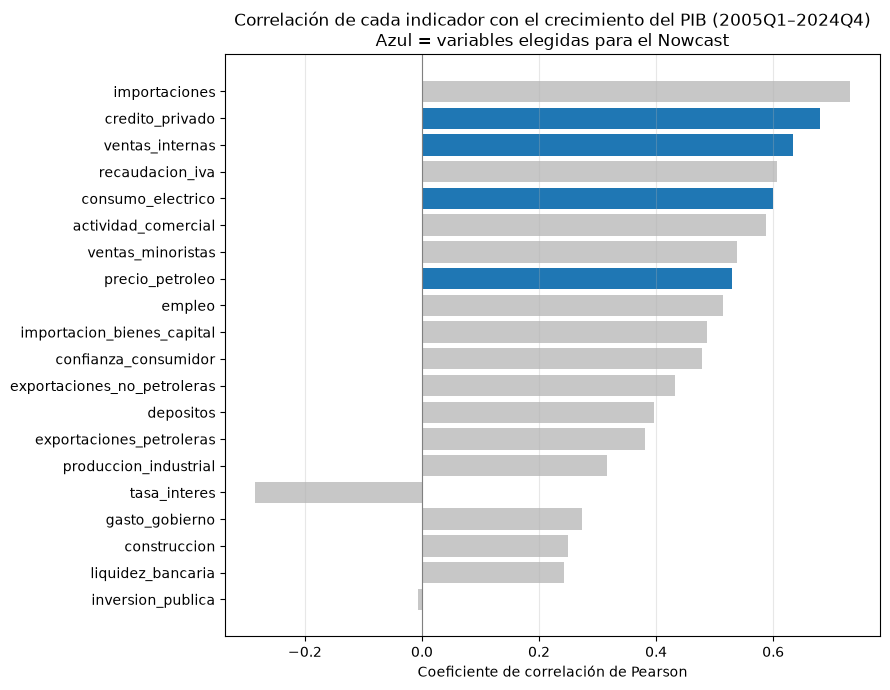

In [4]:
import matplotlib.pyplot as plt

elegidas_estudiante = ["precio_petroleo", "credito_privado", "ventas_internas", "consumo_electrico"]
orden = correlaciones.index[::-1]
colores = ["#1f77b4" if v in elegidas_estudiante else "#c7c7c7" for v in orden]

plt.figure(figsize=(9, 7))
plt.barh(orden, correlaciones.loc[orden, "correlacion_con_PIB"], color=colores)
plt.axvline(0, color="gray", linewidth=0.8)
plt.title("Correlación de cada indicador con el crecimiento del PIB (2005Q1–2024Q4)\nAzul = variables elegidas para el Nowcast")
plt.xlabel("Coeficiente de correlación de Pearson")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [5]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.inspection import permutation_importance

# Random Forest con las 20 candidatas: ¿cuáles usa más el modelo?
rf_todas = Pipeline([
    ("imputar", SimpleImputer(strategy="median")),
    ("modelo", RandomForestRegressor(n_estimators=300, max_depth=5, min_samples_leaf=3,
                                     random_state=2026, n_jobs=-1)),
])
rf_todas.fit(hist_train[candidatas], hist_train["crecimiento_pib"])

importancias = pd.DataFrame({
    "importancia_impureza": rf_todas.named_steps["modelo"].feature_importances_,
}, index=candidatas)

perm = permutation_importance(rf_todas, hist_train[candidatas], hist_train["crecimiento_pib"],
                              n_repeats=20, random_state=2026, scoring="neg_root_mean_squared_error")
importancias["importancia_permutacion"] = perm.importances_mean
importancias = importancias.sort_values("importancia_impureza", ascending=False)
importancias["elegida"] = importancias.index.isin(elegidas_estudiante)
display(importancias.round(4))

print("Participación de las 4 variables elegidas en la importancia total:",
      round(importancias.loc[elegidas_estudiante, "importancia_impureza"].sum() * 100, 1), "%")

,importancia_impureza,importancia_permutacion,elegida
importaciones,0.3561,0.6213,False
credito_privado,0.1694,0.3719,True
consumo_electrico,0.0986,0.1686,True
precio_petroleo,0.0656,0.1256,True
actividad_comercial,0.0393,0.0608,False
exportaciones_no_petroleras,0.0381,0.0777,False
produccion_industrial,0.0352,0.0901,False
recaudacion_iva,0.0339,0.0403,False
ventas_internas,0.0279,0.0350,True
liquidez_bancaria,0.0247,0.0443,False


Participación de las 4 variables elegidas en la importancia total: 36.1 %


In [6]:
from sklearn.model_selection import TimeSeriesSplit, cross_validate

# Comparamos conjuntos alternativos de predictores con la MISMA validación temporal
cv_sel = TimeSeriesSplit(n_splits=4, test_size=4)
top_corr_4 = correlaciones.index[:4].tolist()
top_imp_4 = importancias.index[:4].tolist()

conjuntos = {
    "Elegidas (petróleo, crédito, ventas, electricidad)": elegidas_estudiante,
    "Top-4 por correlación": top_corr_4,
    "Top-4 por importancia RF": top_imp_4,
    "Las 20 candidatas": candidatas,
    "Solo precio_petroleo": ["precio_petroleo"],
    "Elegidas + importaciones": elegidas_estudiante + ["importaciones"],
}
# Prueba de exclusión: quitamos una variable elegida a la vez
for v in elegidas_estudiante:
    conjuntos[f"Sin {v}"] = [w for w in elegidas_estudiante if w != v]

filas = []
for nombre, vars_ in conjuntos.items():
    pipe = Pipeline([
        ("imputar", SimpleImputer(strategy="median")),
        ("modelo", RandomForestRegressor(n_estimators=180, max_depth=5, min_samples_leaf=3,
                                         random_state=2026, n_jobs=-1)),
    ])
    r = cross_validate(pipe, hist_train[vars_], hist_train["crecimiento_pib"], cv=cv_sel,
                       scoring={"MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error"})
    filas.append({"conjunto": nombre, "n_variables": len(vars_), "variables": ", ".join(vars_),
                  "MAE_CV": -r["test_MAE"].mean(), "RMSE_CV": -r["test_RMSE"].mean()})

comparacion_conjuntos = pd.DataFrame(filas).sort_values("RMSE_CV").reset_index(drop=True)
display(comparacion_conjuntos.round(3))

,conjunto,n_variables,variables,MAE_CV,RMSE_CV
0,"Elegidas (petróleo, crédito, ventas, electrici...",4,"precio_petroleo, credito_privado, ventas_inter...",0.976,1.081
1,Sin ventas_internas,3,"precio_petroleo, credito_privado, consumo_elec...",0.957,1.082
2,Sin consumo_electrico,3,"precio_petroleo, credito_privado, ventas_internas",0.987,1.095
3,Sin precio_petroleo,3,"credito_privado, ventas_internas, consumo_elec...",0.999,1.106
4,Elegidas + importaciones,5,"precio_petroleo, credito_privado, ventas_inter...",1.111,1.240
5,Las 20 candidatas,20,"ventas_internas, produccion_industrial, activi...",1.125,1.253
6,Top-4 por importancia RF,4,"importaciones, credito_privado, consumo_electr...",1.127,1.263
7,Top-4 por correlación,4,"importaciones, credito_privado, ventas_interna...",1.180,1.337
8,Sin credito_privado,3,"precio_petroleo, ventas_internas, consumo_elec...",1.180,1.411
9,Solo precio_petroleo,1,precio_petroleo,1.997,2.236


### Conclusión de la selección

Se eligieron cuatro indicadores, uno por cada canal clave de la economía ecuatoriana:

| Variable | Canal económico | ¿Por qué sirve para un nowcast? |
|---|---|---|
| `precio_petroleo` | Sector externo / fiscal | El petróleo es el principal producto de exportación y una fuente central de ingresos fiscales. En una economía dolarizada, su precio determina la entrada de divisas, la liquidez y la capacidad de gasto público. Se observa a diario. |
| `credito_privado` | Sistema financiero | El crédito financia el consumo de los hogares y la inversión de las empresas; anticipa la demanda agregada. Se publica mensualmente. |
| `ventas_internas` | Actividad / demanda | Mide directamente la actividad comercial del mercado interno (declaraciones tributarias); es un reflejo casi contemporáneo del PIB. Mensual. |
| `consumo_electrico` | Actividad real | Indicador físico (no monetario) de la producción industrial, comercial y residencial; disponible casi en tiempo real. |

**Lo que muestra la evidencia (solo entrenamiento 2005Q1–2024Q4):**

* Las cuatro tienen correlación positiva y relevante con el PIB (entre 0,53 y 0,68). `credito_privado`, `consumo_electrico` y `precio_petroleo` están además entre las 4 variables más importantes del Random Forest con las 20 candidatas.
* Con **solo 4 predictores** el modelo obtiene el **menor error de validación cruzada** de todos los conjuntos comparados (RMSE ≈ 1,08), menor que usar las 20 variables (≈ 1,25) o las 4 de mayor correlación (≈ 1,34). Más variables no implica mejor pronóstico: con 80 trimestres, las variables adicionales introducen ruido y sobreajuste.
* La prueba de exclusión (quitar una variable a la vez) muestra el aporte de cada una: sin `credito_privado` el RMSE sube de 1,08 a 1,41 (es el predictor decisivo); sin `precio_petroleo` sube a 1,11 y sin `consumo_electrico` a 1,10.
* `importaciones` tiene la correlación más alta, pero **no se incluyó**: al agregarla, el error fuera de muestra empeora. Económicamente, las importaciones son más una *consecuencia* del nivel de actividad (suben cuando crece el ingreso) que un indicador adelantado, y su relación con el PIB es menos estable en el tiempo.
* `ventas_internas` es el caso más débil: su aporte marginal es prácticamente nulo (sin ella el RMSE queda en 1,082 y el MAE incluso baja levemente), porque comparte información con el crédito y la electricidad. Se mantiene por razones económicas —es la medida más directa de la demanda interna y da robustez si otro indicador llega tarde o con errores—, pero es la primera candidata a revisarse en una próxima versión del modelo.

Finalmente, un conjunto pequeño hace la aplicación más fácil de usar: el analista solo necesita cuatro datos para generar el nowcast del trimestre.

Seleccionar las variables predictoras

In [7]:
# Variable objetivo
TARGET = "crecimiento_pib"

# PERSONALIZACIÓN DEL ESTUDIANTE: cambiar SOLO esta lista.
# Elegir entre 4 y 8 indicadores numéricos existentes en el CSV.
FEATURES = [
    "precio_petroleo",
    "credito_privado",
    "ventas_internas",
    "consumo_electrico"
]

if not 4 <= len(FEATURES) <= 8:
    raise ValueError("Seleccione entre 4 y 8 predictores")
if len(FEATURES) != len(set(FEATURES)):
    raise ValueError("No repita predictores")
faltantes = [v for v in FEATURES + [TARGET, "trimestre"] if v not in historico.columns]
if faltantes:
    raise ValueError(f"Columnas inexistentes: {faltantes}")
no_numericas = [v for v in FEATURES if not pd.api.types.is_numeric_dtype(historico[v])]
if no_numericas:
    raise ValueError(f"Estas variables no son numéricas: {no_numericas}")

print("Variable objetivo:", TARGET)
print("Predictores seleccionados:", FEATURES)


Variable objetivo: crecimiento_pib
Predictores seleccionados: ['precio_petroleo', 'credito_privado', 'ventas_internas', 'consumo_electrico']


In [8]:
# X contiene las variables predictoras
X = historico[FEATURES]

# y contiene la variable objetivo
y = historico[TARGET]

# Verificamos las dimensiones
print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)

# Visualizamos los predictores
display(X.head())

Dimensiones de X: (87, 4)
Dimensiones de y: (87,)


,precio_petroleo,credito_privado,ventas_internas,consumo_electrico
0,67.379,6.302,3.256,2.679
1,64.620,4.723,1.289,2.559
2,74.172,7.036,2.669,3.164
3,66.515,7.695,3.668,2.359
4,65.541,7.717,2.699,3.540


Separar entrenamiento de prueba

In [9]:
# Ordenamos la base cronológicamente
historico = historico.sort_values("trimestre").reset_index(drop=True)

# Volvemos a crear X e y después de ordenar los trimestres
X = historico[FEATURES]
y = historico[TARGET]

# Entrenamiento: 2005Q1 hasta 2024Q4
train = historico[
    historico["trimestre"] <= "2024Q4"
].copy()

# Prueba: 2025Q1 hasta 2026Q3
test = historico[
    historico["trimestre"] >= "2025Q1"
].copy()

# Separamos las variables
X_train = train[FEATURES]
y_train = train[TARGET]

X_test = test[FEATURES]
y_test = test[TARGET]

# Comprobamos las particiones
print("Entrenamiento:", len(train))
print("Prueba:", len(test))

print("Primero en prueba:", test["trimestre"].iloc[0])
print("Último en prueba:", test["trimestre"].iloc[-1])

Entrenamiento: 80
Prueba: 7
Primero en prueba: 2025Q1
Último en prueba: 2026Q3


Construir Preprocesamiento

In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

# Definimos la preparación de variables
preprocesador = ColumnTransformer(
    transformers=[
        (
            "numericas",
            SimpleImputer(strategy="median"),
            FEATURES
        )
    ]
)

In [11]:
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor

pipeline_rf = Pipeline(steps=[
    (
        "preprocesamiento",
        preprocesador
    ),
    (
        "modelo",
        RandomForestRegressor(
            n_estimators=180,
            max_depth=5,
            min_samples_leaf=3,
            max_features=1.0,
            random_state=2026,
            n_jobs=-1
        )
    )
])

print(pipeline_rf)

Pipeline(steps=[('preprocesamiento',
                 ColumnTransformer(transformers=[('numericas',
                                                  SimpleImputer(strategy='median'),
                                                  ['precio_petroleo',
                                                   'credito_privado',
                                                   'ventas_internas',
                                                   'consumo_electrico'])])),
                ('modelo',
                 RandomForestRegressor(max_depth=5, min_samples_leaf=3,
                                       n_estimators=180, n_jobs=-1,
                                       random_state=2026))])


In [12]:
from sklearn.model_selection import TimeSeriesSplit, cross_validate

In [13]:
from sklearn.model_selection import TimeSeriesSplit, cross_validate

# Definimos la validación cruzada temporal
validacion = TimeSeriesSplit(
    n_splits=4,
    test_size=4
)

# Revisamos los períodos de cada partición
for numero, (indices_train, indices_valid) in enumerate(
    validacion.split(X_train), start=1
):
    print("Validación:", numero)

    print(
        "Entrenamiento:",
        train.iloc[indices_train]["trimestre"].iloc[0],
        "hasta",
        train.iloc[indices_train]["trimestre"].iloc[-1]
    )

    print(
        "Validación:",
        train.iloc[indices_valid]["trimestre"].iloc[0],
        "hasta",
        train.iloc[indices_valid]["trimestre"].iloc[-1]
    )

    print("-------------------------")

Validación: 1
Entrenamiento: 2005Q1 hasta 2020Q4
Validación: 2021Q1 hasta 2021Q4
-------------------------
Validación: 2
Entrenamiento: 2005Q1 hasta 2021Q4
Validación: 2022Q1 hasta 2022Q4
-------------------------
Validación: 3
Entrenamiento: 2005Q1 hasta 2022Q4
Validación: 2023Q1 hasta 2023Q4
-------------------------
Validación: 4
Entrenamiento: 2005Q1 hasta 2023Q4
Validación: 2024Q1 hasta 2024Q4
-------------------------


Ejecutamos validación cruzada

In [14]:
# Definimos las métricas de evaluación
metricas = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error"
}

# Ejecutamos la validación cruzada
resultados_cv = cross_validate(
    pipeline_rf,
    X_train,
    y_train,
    cv=validacion,
    scoring=metricas
)

# Convertimos los resultados en una tabla
tabla_cv = pd.DataFrame({
    "Validacion": [1, 2, 3, 4],
    "MAE": -resultados_cv["test_MAE"],
    "RMSE": -resultados_cv["test_RMSE"]
})

display(tabla_cv)

,Validacion,MAE,RMSE
0,1,0.851095,0.884332
1,2,1.298294,1.403993
2,3,0.849781,0.880243
3,4,0.903296,1.155092


In [15]:
print("MAE promedio:", round(tabla_cv["MAE"].mean(), 3))

print("RMSE promedio:", round(tabla_cv["RMSE"].mean(), 3))

MAE promedio: 0.976
RMSE promedio: 1.081


Entrenar el modelo y evaluar la muestra final

In [16]:
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error,
    root_mean_squared_error, r2_score
)

# Entrenamiento con 2005Q1–2024Q4
pipeline_rf.fit(X_train, y_train)

# Predicción de los 7 trimestres reservados
predicciones_test = pipeline_rf.predict(X_test)

# Métricas de prueba
mae_test = mean_absolute_error(y_test, predicciones_test)
mse_test = mean_squared_error(y_test, predicciones_test)
rmse_test = root_mean_squared_error(y_test, predicciones_test)
r2_test = r2_score(y_test, predicciones_test)

print("MAE prueba:", round(mae_test, 3))
print("MSE prueba:", round(mse_test, 3))
print("RMSE prueba:", round(rmse_test, 3))
print("R² prueba:", round(r2_test, 3))

# Creamos el DataFrame de resultados para mostrar
resultados_test = pd.DataFrame({
    "Trimestre": test["trimestre"],
    "PIB_real": y_test,
    "PIB_predicho": predicciones_test,
    "Residuo": y_test - predicciones_test
})

display(resultados_test)

MAE prueba: 0.716
MSE prueba: 0.915
RMSE prueba: 0.957
R² prueba: 0.431


,Trimestre,PIB_real,PIB_predicho,Residuo
80,2025Q1,-2.055,-0.009048,-2.045952
81,2025Q2,-0.617,-0.023996,-0.593004
82,2025Q3,0.768,0.655496,0.112504
83,2025Q4,1.273,0.929258,0.343742
84,2026Q1,-0.659,0.389094,-1.048094
85,2026Q2,-0.800,-0.002602,-0.797398
86,2026Q3,1.840,1.908404,-0.068404


In [17]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    root_mean_squared_error,
    r2_score
)

# MAE
mae_test = mean_absolute_error(
    y_test, predicciones_test
)

# MSE
mse_test = mean_squared_error(
    y_test, predicciones_test
)

# RMSE
rmse_test = root_mean_squared_error(
    y_test, predicciones_test
)

# R cuadrado
r2_test = r2_score(
    y_test, predicciones_test
)

print("MAE prueba:", round(mae_test, 3))
print("MSE prueba:", round(mse_test, 3))
print("RMSE prueba:", round(rmse_test, 3))
print("R² prueba:", round(r2_test, 3))

MAE prueba: 0.716
MSE prueba: 0.915
RMSE prueba: 0.957
R² prueba: 0.431


In [18]:
print("Observaciones en prueba:", len(X_test))
print("Primer trimestre:", test["trimestre"].iloc[0])
print("Último trimestre:", test["trimestre"].iloc[-1])

Observaciones en prueba: 7
Primer trimestre: 2025Q1
Último trimestre: 2026Q3


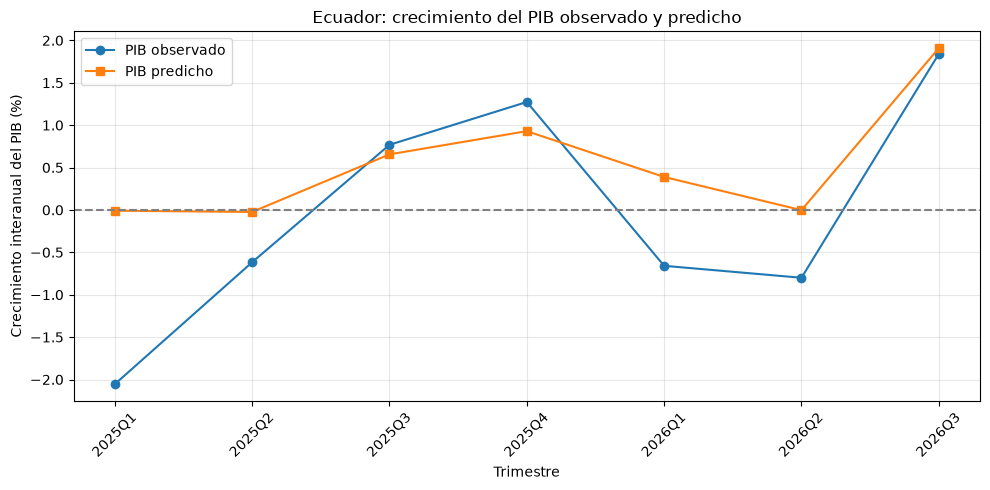

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    resultados_test["Trimestre"],
    resultados_test["PIB_real"],
    marker="o",
    label="PIB observado"
)

plt.plot(
    resultados_test["Trimestre"],
    resultados_test["PIB_predicho"],
    marker="s",
    label="PIB predicho"
)

plt.axhline(0, color="gray", linestyle="--")

plt.title("Ecuador: crecimiento del PIB observado y predicho")
plt.xlabel("Trimestre")
plt.ylabel("Crecimiento interanual del PIB (%)")

plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Experiment Tracker — seguimiento de ejecuciones (sin MLflow)

En esta sección probamos **ocho configuraciones** de Random Forest sobre **las mismas cuatro ventanas de validación cruzada temporal**. Cada configuración se identifica por un `run_id` y sus métricas se guardan en archivos CSV para la aplicación Streamlit.

**Importante:** la selección se basa únicamente en la validación cruzada del conjunto de entrenamiento (hasta 2024Q4). El período 2025Q1–2026Q3 se conserva como prueba independiente y se evalúa **una sola vez después de seleccionar el ganador**. Los resultados no son simulados por este bloque: se calculan al ejecutar el notebook con la base histórica cargada.


In [20]:
from datetime import datetime, timezone
from itertools import product
from sklearn.base import clone
from sklearn.model_selection import cross_validate

# Cuatro particiones temporales de cuatro trimestres, como en el ejercicio original
cv_tracker = TimeSeriesSplit(n_splits=4, test_size=4)

# Cuadrícula pequeña y didáctica: 2 × 2 × 2 = 8 experimentos
combinaciones = list(product([100, 200], [4, 7], [2, 4]))
registros_runs = []
registros_folds = []
fecha_ejecucion = datetime.now(timezone.utc).isoformat(timespec="seconds")

for numero, (arboles, profundidad, hoja) in enumerate(combinaciones, start=1):
    run_id = f"RUN-{numero:03d}"
    candidato = clone(pipeline_rf)
    candidato.set_params(
        modelo__n_estimators=arboles,
        modelo__max_depth=profundidad,
        modelo__min_samples_leaf=hoja
    )
    puntajes = cross_validate(
        candidato, X_train, y_train, cv=cv_tracker,
        scoring={"MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error"},
        error_score="raise"
    )
    maes = -puntajes["test_MAE"]
    rmses = -puntajes["test_RMSE"]
    registros_runs.append({
        "run_id": run_id, "fecha_utc": fecha_ejecucion,
        "modelo": "Random Forest", "n_estimators": arboles,
        "max_depth": profundidad, "min_samples_leaf": hoja,
        "max_features": 1.0, "random_state": 2026,
        "n_splits": 4, "test_size": 4,
        "periodo_entrenamiento_fin": str(train["trimestre"].iloc[-1]),
        "n_variables": len(FEATURES), "variables": ", ".join(FEATURES),
        "mae_cv": float(maes.mean()), "rmse_cv": float(rmses.mean()),
        "std_rmse_cv": float(rmses.std(ddof=1)),
    })
    for fold, (mae, rmse) in enumerate(zip(maes, rmses), start=1):
        indices_train, indices_valid = list(cv_tracker.split(X_train))[fold-1]
        registros_folds.append({
            "run_id": run_id, "fold": fold,
            "fin_entrenamiento": str(train.iloc[indices_train]["trimestre"].iloc[-1]),
            "inicio_validacion": str(train.iloc[indices_valid]["trimestre"].iloc[0]),
            "fin_validacion": str(train.iloc[indices_valid]["trimestre"].iloc[-1]),
            "mae": float(mae), "rmse": float(rmse)
        })

experimentos = pd.DataFrame(registros_runs).sort_values(["rmse_cv", "mae_cv"]).reset_index(drop=True)
experimentos["ranking"] = range(1, len(experimentos)+1)
experimentos["es_mejor"] = experimentos["ranking"] == 1
folds_experimentos = pd.DataFrame(registros_folds)

display(experimentos[["run_id", "n_estimators", "max_depth", "min_samples_leaf", "mae_cv", "rmse_cv", "ranking"]])


,run_id,n_estimators,max_depth,min_samples_leaf,mae_cv,rmse_cv,ranking
0,RUN-003,100,7,2,0.923641,1.019223,1
1,RUN-007,200,7,2,0.946759,1.044938,2
2,RUN-001,100,4,2,0.993926,1.098730,3
3,RUN-005,200,4,2,1.003794,1.112439,4
4,RUN-004,100,7,4,1.008598,1.116670,5
5,RUN-008,200,7,4,1.013061,1.124975,6
6,RUN-002,100,4,4,1.028889,1.143337,7
7,RUN-006,200,4,4,1.031227,1.148241,8


In [21]:
# Seleccionamos el mejor modelo usando ÚNICAMENTE validación cruzada
mejor = experimentos.iloc[0]
mejor_run_id = mejor["run_id"]
modelo_ganador = clone(pipeline_rf).set_params(
    modelo__n_estimators=int(mejor["n_estimators"]),
    modelo__max_depth=int(mejor["max_depth"]),
    modelo__min_samples_leaf=int(mejor["min_samples_leaf"])
)

# Evaluación final del ganador en el período de prueba reservado
modelo_ganador.fit(X_train, y_train)
predicciones_ganador = modelo_ganador.predict(X_test)
metricas_ganador_test = {
    "run_id": mejor_run_id,
    "mae_test": float(mean_absolute_error(y_test, predicciones_ganador)),
    "rmse_test": float(root_mean_squared_error(y_test, predicciones_ganador)),
    "r2_test": float(r2_score(y_test, predicciones_ganador)),
    "n_test": len(X_test),
    "inicio_test": str(test["trimestre"].iloc[0]),
    "fin_test": str(test["trimestre"].iloc[-1]),
}

# No comparamos múltiples modelos con el test para volver a elegir.
print("Run seleccionado por validación cruzada:", mejor_run_id)
print("RMSE CV:", round(float(mejor["rmse_cv"]), 3))
print("RMSE prueba independiente:", round(metricas_ganador_test["rmse_test"], 3))

test_ganador = pd.DataFrame({
    "trimestre": test["trimestre"].to_numpy(),
    "pib_observado": y_test.to_numpy(),
    "pib_predicho": predicciones_ganador,
})
test_ganador["error"] = test_ganador["pib_observado"] - test_ganador["pib_predicho"]


Run seleccionado por validación cruzada: RUN-003
RMSE CV: 1.019
RMSE prueba independiente: 0.83


In [22]:
# Archivos que alimentarán el nuevo panel de Streamlit
from pathlib import Path
import json

carpeta_salidas = Path("salidas_tracker")
carpeta_salidas.mkdir(exist_ok=True)
experimentos.to_csv(carpeta_salidas / "experimentos.csv", index=False)
folds_experimentos.to_csv(carpeta_salidas / "experimentos_folds.csv", index=False)
test_ganador.to_csv(carpeta_salidas / "predicciones_test_ganador.csv", index=False)
with open(carpeta_salidas / "mejor_experimento.json", "w", encoding="utf-8") as archivo:
    json.dump({
        "run_id": mejor_run_id,
        "parametros": {
            "n_estimators": int(mejor["n_estimators"]),
            "max_depth": int(mejor["max_depth"]),
            "min_samples_leaf": int(mejor["min_samples_leaf"])
        },
        "metricas_cv": {
            "mae": float(mejor["mae_cv"]),
            "rmse": float(mejor["rmse_cv"])
        },
        "metricas_test": metricas_ganador_test,
        "features": FEATURES
    }, archivo, indent=2, ensure_ascii=False)

print("Archivos disponibles:")
for archivo in carpeta_salidas.iterdir():
    print("-", archivo)

# Descargar todos los resultados juntos desde Colab (opcional)
# !zip -r salidas_tracker.zip salidas_tracker
# from google.colab import files
# files.download("salidas_tracker.zip")

# Configuración que Streamlit utilizará para crear formularios dinámicos.
config_modelo = {
    "modelo": "Random Forest",
    "target": TARGET,
    "features": FEATURES,
    "run_id": mejor_run_id,
    "periodicidad": "trimestral",
    "datos": "simulados",
    "version_config": 1
}
with open(carpeta_salidas / "config_modelo.json", "w", encoding="utf-8") as archivo:
    json.dump(config_modelo, archivo, indent=2, ensure_ascii=False)
print("Configuración del modelo exportada:", config_modelo)


Archivos disponibles:
- salidas_tracker\config_modelo.json
- salidas_tracker\experimentos.csv
- salidas_tracker\experimentos_folds.csv
- salidas_tracker\mejor_experimento.json
- salidas_tracker\predicciones_test_ganador.csv
Configuración del modelo exportada: {'modelo': 'Random Forest', 'target': 'crecimiento_pib', 'features': ['precio_petroleo', 'credito_privado', 'ventas_internas', 'consumo_electrico'], 'run_id': 'RUN-003', 'periodicidad': 'trimestral', 'datos': 'simulados', 'version_config': 1}


### Entrenamiento final y exportación

El modelo se reentrena con toda la historia observada. **Suba el archivo `modelo_pib.joblib` junto con `config_modelo.json` y los CSV de `salidas_tracker/` al mismo repositorio**. La configuración se deriva de la selección real de predictores y no se debe modificar por separado.


In [23]:
# Reentrenamos el mejor pipeline con TODA la historia observada
pipeline_rf = clone(modelo_ganador)
pipeline_rf.fit(X, y)

print("Modelo final entrenado correctamente")
print("Run ganador:", mejor_run_id)
print("Observaciones utilizadas:", len(X))
print("Variables utilizadas:", FEATURES)


Modelo final entrenado correctamente
Run ganador: RUN-003
Observaciones utilizadas: 87
Variables utilizadas: ['precio_petroleo', 'credito_privado', 'ventas_internas', 'consumo_electrico']


In [24]:
import joblib

# Guardamos el pipeline completo
joblib.dump(
    pipeline_rf,
    "modelo_pib.joblib"
)

print("Pipeline guardado correctamente")

Pipeline guardado correctamente


In [25]:
# Descarga del modelo (solo disponible dentro de Google Colab)
try:
    from google.colab import files
    files.download("modelo_pib.joblib")
except ImportError:
    print("Ejecución fuera de Colab: modelo_pib.joblib quedó guardado en la carpeta de trabajo.")

Ejecución fuera de Colab: modelo_pib.joblib quedó guardado en la carpeta de trabajo.


In [26]:
import sys
import sklearn
import numpy
import pandas
import joblib

print("Python:", sys.version.split()[0])
print("scikit-learn:", sklearn.__version__)
print("numpy:", numpy.__version__)
print("pandas:", pandas.__version__)
print("joblib:", joblib.__version__)

Python: 3.12.3
scikit-learn: 1.9.1
numpy: 2.5.4
pandas: 3.1.1
joblib: 1.6.0
